In [ ]:
import os
import sys
import joblib

import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.constants import Configs
from utils.loso_models.zscore_detector import ZScoreDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.helper_functions import load_outlier_data
from utils.metrics import movement_level_confusion
from utils.helper_functions import calculate_trash_percentage
from utils.plotting import plot_movement_data
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Pick'
ALGORITHM_NAME = 'ZScore'
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [3]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)
print(f"Number of movements: {n_movements}")

Number of movements: 380


In [4]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 2 positivos / 380 movimentos = 0.53%
GT R: 2 positivos / 380 movimentos = 0.53%
GT OR: 3 positivos / 380 movimentos = 0.79%


### Load Features from Csv

In [ ]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()
n_movements_f = len(features_df)
total_trials = features_df.drop_duplicates(subset=['sub', 'repID']).shape[0]

assert not np.isnan(X_features).any(), "NaN in features"
assert len(features_df) == n_movements, (len(features_df), n_movements)
assert set(map(tuple, features_df[Configs.KEYS].values)) == base_keys
print(X_features.shape)

(380, 43)


In [6]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

# Ground truth used for evalution on this run
GT_KEY = 'OR'  # TODO isto vai ter de ficar noutro local, mas por agora é só para testar
gt_used = GT[GT_KEY]
total_known_outliers = len(gt_used)

# Movement-level anomalies
known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
known_percentage = known_outlier_rate * 100

# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")
print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")

Phase: Pick
positives by ground truth: {'L': 2, 'R': 2, 'OR': 3}
GT used (Union): 3 positives / 380 movements = 0.79%


### Normality Test

--- Shapiro-Wilk Test Results ---
Feature         | P-Value      | Conclusion
---------------------------------------------
duration        | 0.000000 | Not Normal
range_x_L       | 0.000000 | Not Normal
range_y_L       | 0.000000 | Not Normal
range_z_L       | 0.000000 | Not Normal
path_length_L   | 0.000000 | Not Normal
path_ratio_L    | 0.000000 | Not Normal
mean_vel_L      | 0.000000 | Not Normal
max_vel_L       | 0.000000 | Not Normal
time_to_peak_vel_L | 0.000000 | Not Normal
mean_to_peak_vel_ratio_L | 0.000000 | Not Normal
vel_skewness_L  | 0.433260 | Normal
n_velocity_peaks_L | 0.000000 | Not Normal
mean_acc_L      | 0.000000 | Not Normal
max_acc_L       | 0.000000 | Not Normal
max_jerk_L      | 0.000000 | Not Normal
ldlj_L          | 0.017047 | Not Normal
sparc_L         | 0.000000 | Not Normal
total_curvature_L | 0.000000 | Not Normal
total_torsion_L | 0.000000 | Not Normal
range_x_R       | 0.000000 | Not Normal
range_y_R       | 0.000000 | Not Normal
range_z_R       | 0.000



In [7]:
fig, axes = plt.subplots(len(Configs.FEATURE_COLS), 2, figsize=(10, 3 * len(Configs.FEATURE_COLS)))

print("--- Shapiro-Wilk Test Results ---")
print(f"{'Feature':<15} | {'P-Value':<12} | {'Conclusion'}")
print("-" * 45)

for i, col in enumerate(Configs.FEATURE_COLS):
    data = features_df[col].dropna() # Remove NaNs for safety
    
    # Statistical Test (Shapiro-Wilk)
    # Note: For N > 5000, Shapiro becomes too sensitive. 
    # If you have a lot of data, use stats.normaltest() (D'Agostino's K^2)
    stat, p_value = stats.shapiro(data)
    
    is_normal = p_value > 0.05
    conclusion = "Normal" if is_normal else "Not Normal"
    
    print(f"{col:<15} | {p_value:.6f} | {conclusion}")

    # Left: Histogram + KDE
    sns.histplot(data, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram: {col}')
    
    # Right: Q-Q Plot 
    stats.probplot(data, dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'Q-Q Plot: {col}')

plt.tight_layout()
plt.show()

## Z-Score Feature Extraction

This is not a machine learning algorithm, so it does not have any hyperparameters to grid search. Maybe the LOSO pipeline is not necessary.

In [8]:
def modified_zscore(series):
    """
    Como aparentemente os meus dados não seguem uma distribuição normal, o Z-Score tradicional pode ser enganador.
    O Modified Z-Score é uma alternativa robusta que usa a mediana e o MAD (Median Absolute Deviation) em vez da média e do desvio padrão, tornando-o menos sensível a outliers.
    """
    median = np.median(series)
    mad = median_abs_deviation(series)
    
    # If MAD is 0 (all values are identical), return 0 to avoid division by zero
    if mad == 0:
        return np.zeros(len(series))

    # The constant 0.6745 makes the MAD comparable to the standard deviation
    modified_z = 0.6745 * (series - median) / mad
    return modified_z

### Grid Search

In [ ]:
print("\n--- Starting LOSO Baseline: Z-Score (Features) ---")

Z_THRESHOLDS = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2.0, 2.5, 3.0]
param_grid_z = [{'z_threshold': z} for z in Z_THRESHOLDS]

loso_results = run_loso_evaluation(
    detector_class=ZScoreDetector, 
    param_grid=param_grid_z,
    data_matrix=X_features,                     # all features
    metadata_df=features_df[Configs.META_COLS], # same rows as X_features
    known_outliers_df=gt_used,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),

)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)


--- Starting LOSO Baseline: Z-Score (Features) ---
LOSO Cross-Validation with 19 subjects (3 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Avaliação Estatística - Bootstraping

In [10]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [11]:
append_experiment_record(
    summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, GT_KEY),
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=n_movements,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for ZScore - FeatureBased - Pick - 380 Movements (MOVEMENT-level):
Unique Outliers Detected: 155
Rejection Rate: 40.79%
Known Positives in Ground Truth: 3
------------------------------
Total True Positives (Global):  2
Total False Positives (Global): 153
Total False Negatives (Global): 1
Total True Negatives (Global):  224
------------------------------
Blind Precision: 1.29 [0.00–3.15]
Blind Recall:    66.67 [0.00–100.00]
Blind F1-Score:  2.53
Blind F2-Score:  5.99 [0.00–13.65]
Blind MCC:       0.05 [-0.05–0.13]
Blind AUPRC:  12.39 [0.72–33.33]
Blind AUROC:   77.19

Total Tuning Time (19 Subjects): 1.8013s
Total Inference Time (19 Subjects): 0.0152s

Overall Best Parameters (Most frequent across folds):
   {'z_threshold': 1.75}
Occurrences: 12


### Tarin Model

In [ ]:
best_params = loso_results["Best_Params"]
best_z_threshold = best_params['z_threshold']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

Dropped features: ['max_acc', 'max_vel', 'mean_acc', 'path_length', 'vel_skewness', 'wrist_dist_min']


In [ ]:
final_z_model = ZScoreDetector(metric_type='euclidean', z_threshold=best_z_threshold)
labels = final_z_model.fit_predict(X_features_scaled_full)
joblib.dump(final_z_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# Trick to fit old code (where outliers were marked as True/False instead of -1/1)
features_df['is_outlier'] = (labels == -1)

# Calculate trial-level metrics
n_outliers = features_df['is_outlier'].sum()
n_raw_outlier_rows = features_df['is_outlier'].sum()
outlier_details = features_df[features_df['is_outlier']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(
    features_df, total_trials, anomaly_col='is_outlier', outlier_value=True
)

print(f"Raw outlier rows detected (Z > {best_z_threshold}): {n_outliers}")
print(f"Unique outlier trials detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/len(features_df)*100):.2f}%") # instead of total_trials, I might have len(dtw_matrix)
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw outlier rows detected (Z > 1.75): 189
Unique outlier trials detected: 85
Detected Outlier Percentage (sub + repID + movID): 49.74%
Detected Outlier Percentage (sub + repID): 89.47%


In [15]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outlier_details.index, cols_to_extract].copy()

print("Outliers metadata:")
print(outliers_metadata_df)

Outliers metadata:
     sub  repID  movID
0      1      1      1
1      1      1      3
2      1      1      5
3      1      1      7
5      1      2      3
..   ...    ...    ...
345   18      2      3
350   18      3      5
353   18      4      3
360   19      1      1
377   19      5      3

[189 rows x 3 columns]


In [ ]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = movement_level_confusion(features_df, np.where(labels == -1)[0], gt_used, Configs.KEYS)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 3
False Positives (Identified, not in CSV): 82
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 10
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 3/85 (3.53%)
Recall (True Positive Rate): 3/3 (100.00%)
F1-Score: 6.82%
F2-Score: 15.46%


In [ ]:
outlier_ids = features_df[features_df['is_outlier'] == True][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['is_outlier'] == True]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; do not permanently alter the original df if unnecessary
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


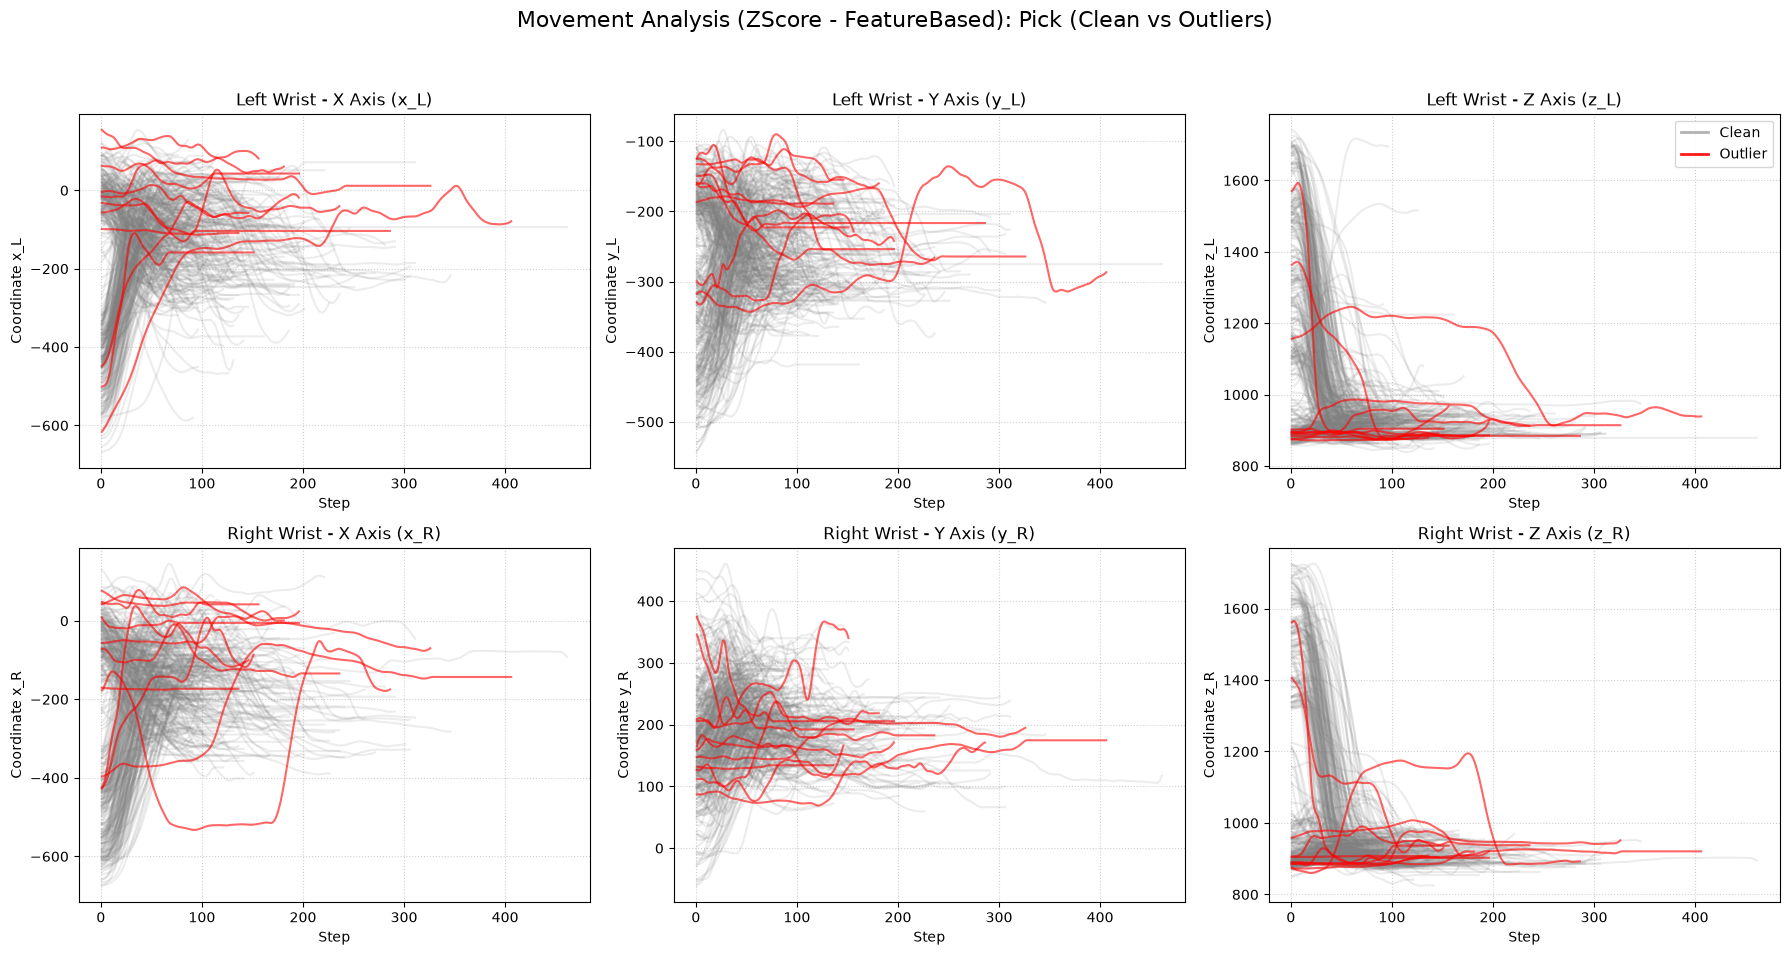

In [ ]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [ ]:
# Limpeza: remover coluna auxiliar
df.drop(columns=['temp_key'], inplace=True)